<a href="https://colab.research.google.com/github/carlocamilloni/Structural-Bioinformatics/blob/main/Notebooks/t07_QM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum chemistry with ORCA

In the previous practicals atoms were classical balls connected by springs: a **force field** gives the energy of a molecule with simple functions (bonds, angles, torsions, point charges, Lennard-Jones). It is fast, but it has two limits: bonds can never break or form, and the parameters must come from somewhere else (to a large extent, from quantum-mechanical calculations).

In this practical we go one level down and treat the **electrons** explicitly, with **quantum mechanics** (QM). Electrons are what chemistry is made of: they make the bonds, they decide the shape and the charge distribution of a molecule, how strongly two molecules stick together, which reactions happen, and which colours a molecule absorbs. A QM calculation gives all of this from first principles: you only give the positions of the nuclei, their charges and the number of electrons.

The price is the cost: a QM calculation is many orders of magnitude more expensive than a force field, so we will work with small molecules (from 1 to about 50 atoms). The figure shows the methods we use: each one is an approximation of the exact solution, with its own balance between accuracy and cost.


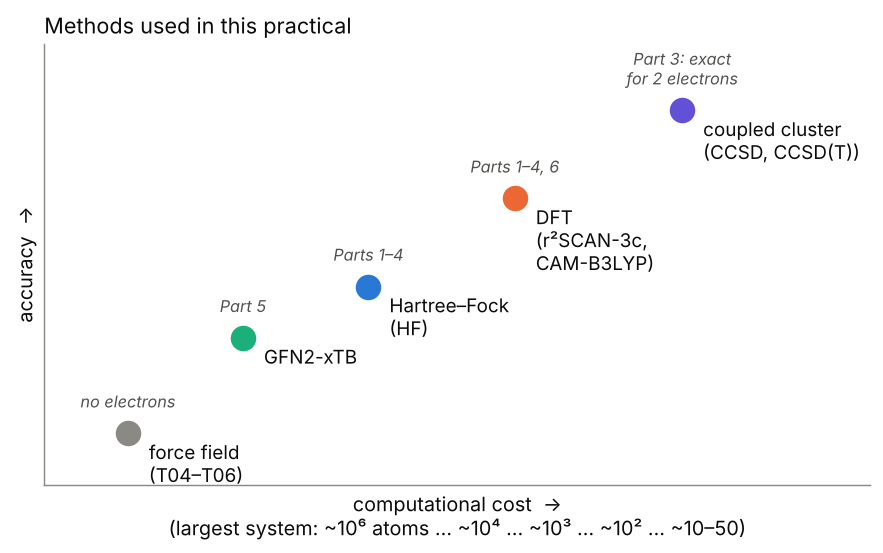

We use [ORCA](https://www.faccts.de/orca/), one of the most widely used quantum-chemistry programs, free for academic use. The reference lecture is:

*   https://github.com/carlocamilloni/Structural-Bioinformatics/blob/main/Notes/08_QM_MM_more.pdf

**Plan of the training** (everybody runs it; each part takes a few minutes)

1.  **The hydrogen atom**: wavefunction and electron density, basis sets, how a QM program finds the electrons.
2.  **The carbon atom**: electron spin.
3.  **The chemical bond in H$_2$**: bonding orbitals, where the bond electrons are, and what happens when a bond breaks.
4.  **A real molecule, water**: shape, vibrations, charges, and the energy of a hydrogen bond.
5.  **Dynamics**: a proton travelling along a chain of water molecules (the Grotthuss mechanism).
6.  **Light**: why some molecules absorb light and have a colour.

The report has **two different exercises**: **GROUP 1** studies the **interactions between molecules** (hydrogen bonds and stacking of DNA bases and aromatic side chains), starting from Part 4, and **GROUP 2** the **colour** of biological chromophores (GFP, retinal, flavins), starting from Part 6.

**Units.** Quantum chemistry uses *atomic units*: energies are in Hartree (1 E$_h$ = 27.211 eV = 627.51 kcal/mol = 2625.5 kJ/mol) and lengths in bohr (1 bohr = 0.529 Å). ORCA reads coordinates in Å. As a reference, the thermal energy $k_BT$ at room temperature is 0.6 kcal/mol, a hydrogen bond is worth a few kcal/mol and a covalent bond about 100 kcal/mol.

## Preliminary setup

All the calculations of the training are small and run on the CPU, you don't need a GPU. Colab gives you 2 CPU cores; we run ORCA on one core (simpler and robust), the timings given below refer to this setting.

### Installing ORCA

[ORCA](https://www.faccts.de/orca/) is free for academic use, but **it cannot be redistributed**: everybody has to download their own copy. You do this only once:

1. Register on the [ORCA forum](https://orcaforum.kofo.mpg.de) with your university e-mail and accept the licence (the account is activated in a few minutes).
2. In `Downloads`, open the folder of the most recent ORCA 6 version and download the **Linux, x86-64, shared-version** archive (`.tar.xz`), a file with a name like `orca_6_1_1_linux_x86-64_shared_openmpi418_nodmrg.tar.xz` (about 600 MB; the `avx2` variant is fine too). Don't take the macOS, Windows or ARM versions, nor the installer (`.run`): Colab runs Linux on x86-64 processors.
3. Upload the archive to your Google Drive, in the folder `MyDrive/Structural_Bioinformatics/ORCA` (create it if needed). Don't unpack it.

The licence is personal: **don't share your copy** with other people (and don't put it in a shared folder).

The next cell mounts your Google Drive, finds the archive and unpacks it in the virtual machine (1–2 minutes). Colab forgets everything at the end of the session: **run it again every time you start a new session**. If you run the notebook on your own Linux computer and ORCA is already installed, set the variable `ORCA_DIR` to the ORCA folder (the one containing the program `orca`) and the cell only checks the installation.

In [ ]:
import os, glob, shutil, subprocess

ORCA_DIR = os.environ.get('ORCA_DIR', '')      # on your own computer: the folder containing the program orca
DRIVE_FOLDER = '/content/drive/MyDrive/Structural_Bioinformatics'

if not (ORCA_DIR and os.path.isfile(os.path.join(ORCA_DIR, 'orca'))):
    from google.colab import drive
    drive.mount('/content/drive')
    archives = sorted(glob.glob(os.path.join(DRIVE_FOLDER, 'ORCA', 'orca_6*linux_x86-64*.tar.*')))
    if not archives:
        raise FileNotFoundError('No ORCA archive found in ' + os.path.join(DRIVE_FOLDER, 'ORCA') +
                                ': follow the instructions above to download it.')
    archive = archives[-1]                        # if there is more than one, take the most recent version
    ORCA_DIR = os.path.join('/content', os.path.basename(archive).split('.tar')[0])
    if not os.path.isfile(os.path.join(ORCA_DIR, 'orca')):
        print('unpacking', os.path.basename(archive), '...')
        subprocess.run(['tar', '-xf', archive, '-C', '/content'], check=True)
    # some archives contain an additional folder level
    found = glob.glob(os.path.join('/content', 'orca_6*', '**', 'orca'), recursive=True)
    ORCA_DIR = os.path.dirname(sorted(found)[-1])

# ORCA must be called with its full path; the shared version also needs its libraries
os.environ['PATH'] = ORCA_DIR + ':' + os.environ['PATH']
os.environ['LD_LIBRARY_PATH'] = ORCA_DIR + ':' + os.environ.get('LD_LIBRARY_PATH', '')
os.environ['OMP_NUM_THREADS'] = '1'
ORCA = os.path.join(ORCA_DIR, 'orca')
version = subprocess.run([ORCA, '--version'], capture_output=True, text=True).stdout.strip()
print('ORCA found in', ORCA_DIR)
print(version if version else 'ORCA is installed')

We also install `py3Dmol` to look at molecules, orbitals and densities directly in the notebook.

In [ ]:
%pip install -q py3Dmol

The calculations run in the folder `T07` on the local disk of the virtual machine (fast), and the results (inputs, outputs, structures, cube files) are **copied automatically to your Google Drive**, in `MyDrive/Structural_Bioinformatics/T07`: they survive the end of the Colab session, and the report notebook finds the calculations of the training there. When you start a new session, this cell copies them back. (We don't run ORCA directly on Google Drive: ORCA writes many temporary files, and Drive is too slow for that.) On your own computer the folder `T07` is made next to the notebook. The cell can be run more than once.

In [ ]:
if 'BASE_DIR' not in globals():          # remember where we started: running this cell again does not go one folder deeper
    BASE_DIR = os.getcwd()
if os.path.isdir('/content/drive/MyDrive'):          # on Colab, with Google Drive mounted
    local_path = '/content/T07'
    DRIVE_PATH = os.path.join(DRIVE_FOLDER, 'T07')
    os.makedirs(DRIVE_PATH, exist_ok=True)
    shutil.copytree(DRIVE_PATH, local_path, dirs_exist_ok=True)    # bring back the results of previous sessions
else:
    local_path = os.path.join(BASE_DIR, 'T07')
    DRIVE_PATH = None
os.makedirs(local_path, exist_ok=True)
%cd $local_path
print('results are saved in', DRIVE_PATH if DRIVE_PATH else local_path)

# the input structures are in the Data/qm folder of the course repository:
# if this notebook is run from a copy of the repository we use it, otherwise we download the repository
if os.path.isdir(os.path.join(BASE_DIR, '..', 'Data', 'qm', 's22')):
    REPO_DIR = os.path.abspath(os.path.join(BASE_DIR, '..'))
else:
    REPO_DIR = '/content/sb' if os.path.isdir('/content') else os.path.join(BASE_DIR, 'sb')
    if os.path.isdir(REPO_DIR):
        !cd "$REPO_DIR" && git pull -q
    else:
        !git clone -q --depth 1 https://github.com/carlocamilloni/Structural-Bioinformatics.git "$REPO_DIR"
QM_DIR = os.path.join(REPO_DIR, 'Data', 'qm')
print('input files from', QM_DIR)

### A few helper functions

ORCA reads a text **input file** (`name.inp`) and writes a long text **output file** (`name.out`), plus a few other files that start with the same name. The input always has the same structure:

```
! method basis-set other-keywords        <- the "simple input" line(s)
%block                                   <- optional blocks with more detailed settings
  keyword value
end
* xyz charge multiplicity                <- the molecule: charge, spin multiplicity and Cartesian coordinates in Å
H  0.0  0.0  0.0
*
```

The functions below write the input, run ORCA, and extract the numbers we need from the output. Read them: they are short and there is nothing magic in them. Every calculation is run in its own folder, so that the files of different calculations don't mix. If a calculation has already been run with the same input (its output exists and ends normally), it is **not run again**: this saves a lot of time when you rerun the notebook. Use `rerun=True` to force a new run.

In [ ]:
import re, time
import numpy as np
import matplotlib.pyplot as plt
import py3Dmol

HARTREE2EV = 27.211386        # 1 Eh in eV
HARTREE2KCAL = 627.5095       # 1 Eh in kcal/mol
BOHR2ANG = 0.529177           # 1 bohr in Å

def save_to_drive(workdir):
    # copy the useful files of a calculation (not the large temporary ones) to the same folder on Google Drive
    if not DRIVE_PATH:
        return
    target = os.path.join(DRIVE_PATH, os.path.relpath(os.path.abspath(workdir), local_path))
    os.makedirs(target, exist_ok=True)
    for f in os.listdir(workdir):
        if f.endswith(('.inp', '.out', '.xyz', '.cube', '.csv', '.hess')):
            shutil.copy2(os.path.join(workdir, f), target)

def run_orca(name, inp, folder='.', rerun=False):
    # write folder/name/name.inp, run ORCA in folder/name and return the path of the output file
    workdir = os.path.join(folder, name)
    os.makedirs(workdir, exist_ok=True)
    out = os.path.join(workdir, name + '.out')
    inpfile = os.path.join(workdir, name + '.inp')
    inp = inp.strip() + '\n'
    if (not rerun and os.path.isfile(out) and 'ORCA TERMINATED NORMALLY' in open(out).read()
            and os.path.isfile(inpfile) and open(inpfile).read() == inp):
        print(f'{name}: already done, reading {out}')
        return out
    for f in os.listdir(workdir):            # a new run starts from an empty folder
        if os.path.isfile(os.path.join(workdir, f)):
            os.remove(os.path.join(workdir, f))
    with open(inpfile, 'w') as f:
        f.write(inp)
    t0 = time.time()
    with open(out, 'w') as f:
        subprocess.run([ORCA, name + '.inp'], cwd=workdir, stdout=f, stderr=subprocess.STDOUT)
    text = open(out).read()
    if 'ORCA TERMINATED NORMALLY' not in text:
        print(text[-3000:])
        raise RuntimeError(f'ORCA did not terminate normally: look at the end of {out}')
    print(f'{name}: done in {time.time() - t0:.1f} s')
    save_to_drive(workdir)
    return out

def xyz_block(xyzfile, ghost=()):
    # the coordinate lines of an xyz file; the atoms whose index is in ghost become ghost atoms (see Part 4)
    lines = open(xyzfile).read().splitlines()
    natoms = int(lines[0])
    atoms = []
    for i, l in enumerate(lines[2:2 + natoms]):
        el, x, y, z = l.split()[:4]
        atoms.append(f'{el}{":" if i in ghost else " "} {x:>12} {y:>12} {z:>12}')
    return '\n'.join(atoms)

def final_energy(out):
    # the last 'FINAL SINGLE POINT ENERGY' of an output (in Eh)
    return float(re.findall(r'FINAL SINGLE POINT ENERGY\s+(-?\d+\.\d+)', open(out).read())[-1])

def wall_time(out):
    # total run time of a calculation, in seconds
    d, h, m, s, ms = re.findall(r'TOTAL RUN TIME:\s+(\d+) days (\d+) hours (\d+) minutes (\d+) seconds (\d+) msec', open(out).read())[-1]
    return 86400*int(d) + 3600*int(h) + 60*int(m) + int(s) + int(ms)/1000

def s2(out):
    # expectation value of S^2 (only for UHF/UKS calculations)
    return float(re.findall(r'Expectation value of <S\*\*2>\s*:\s*(-?\d+\.\d+)', open(out).read())[-1])

def dipole(out):
    # magnitude of the dipole moment, in Debye
    return float(re.findall(r'Magnitude \(Debye\)\s*:\s*(\d+\.\d+)', open(out).read())[-1])

def orbital_energies(out):
    # the last table of orbital energies: list of (occupation, energy in eV); for UHF the spin-up orbitals
    text = open(out).read().split('ORBITAL ENERGIES')[-1]
    rows = []
    for l in text.splitlines()[4:]:
        f = l.split()
        if len(f) != 4:
            if rows: break
            continue
        rows.append((float(f[1]), float(f[3])))
    return rows

def charges(out, kind='MULLIKEN'):
    # atomic charges: kind is MULLIKEN, LOEWDIN, HIRSHFELD (needs the keyword Hirshfeld) or CHELPG (keyword CHELPG)
    text = open(out).read()
    if kind == 'MULLIKEN':
        block = text.split('MULLIKEN ATOMIC CHARGES')[-1].split('Sum of atomic charges')[0]
    elif kind == 'LOEWDIN':
        block = text.split('LOEWDIN ATOMIC CHARGES')[-1].split('LOEWDIN REDUCED')[0]
    elif kind == 'HIRSHFELD':
        block = text.split('HIRSHFELD ANALYSIS')[-1].split('TOTAL')[0]
    elif kind == 'CHELPG':
        block = text.split('CHELPG Charges')[-1].split('Total charge')[0]
    return [(el, float(q)) for el, q in re.findall(r'^\s*\d+\s+([A-Z][a-z]?)\s*:?\s+(-?\d+\.\d+)', block, re.M)]

def read_xyz(xyzfile):
    lines = open(xyzfile).read().splitlines()
    n = int(lines[0])
    el = [l.split()[0] for l in lines[2:2+n]]
    xyz = np.array([[float(v) for v in l.split()[1:4]] for l in lines[2:2+n]])
    return el, xyz

def read_cube(cubefile):
    # Gaussian cube file -> (origin, axes, values); origin and axes in bohr
    with open(cubefile) as f:
        f.readline(); f.readline()
        n, *origin = f.readline().split()
        natoms = abs(int(n))
        axes, shape = [], []
        for _ in range(3):
            npt, *v = f.readline().split()
            shape.append(int(npt)); axes.append([float(x) for x in v])
        for _ in range(natoms):
            f.readline()
        data = np.array(f.read().split(), dtype=float)
    return np.array(origin, dtype=float), np.array(axes), data[-np.prod(shape):].reshape(shape)

def show_molecule(xyzfile, width=400, height=300):
    view = py3Dmol.view(width=width, height=height)
    view.addModel(open(xyzfile).read(), 'xyz')
    view.setStyle({'stick': {'radius': 0.15}, 'sphere': {'scale': 0.25}})
    view.zoomTo()
    return view.show()

def cube_for_display(cubefile, maxpoints=40):
    # the text of a cube file with at most maxpoints per side and 4 digits: much smaller in the notebook
    with open(cubefile) as f:
        lines = f.readlines()
    natoms = abs(int(lines[2].split()[0]))
    origin, axes, data = read_cube(cubefile)
    step = [max(1, int(np.ceil(n / maxpoints))) for n in data.shape]
    data = data[::step[0], ::step[1], ::step[2]]
    head = lines[:2] + [lines[2]]
    for i in range(3):
        v = axes[i] * step[i]
        head.append(f'{data.shape[i]:5d} {v[0]:12.6f} {v[1]:12.6f} {v[2]:12.6f}\n')
    head += lines[6:6 + natoms]
    values = data.ravel()
    body = '\n'.join(' '.join(f'{x:.4g}' for x in values[k:k + 6]) for k in range(0, len(values), 6))
    return ''.join(head) + body + '\n'

def cube_atoms_xyz(cubefile):
    # the atoms stored in a cube file (in bohr) as an xyz text (in Å)
    elements = {1: 'H', 6: 'C', 7: 'N', 8: 'O', 16: 'S'}
    with open(cubefile) as f:
        lines = f.readlines()
    natoms = abs(int(lines[2].split()[0]))
    atoms = []
    for l in lines[6:6 + natoms]:
        z, _, x, y, w = l.split()[:5]
        atoms.append(f'{elements.get(int(float(z)), "X")} {float(x) * BOHR2ANG:.4f} {float(y) * BOHR2ANG:.4f} {float(w) * BOHR2ANG:.4f}')
    return f'{natoms}\n\n' + '\n'.join(atoms) + '\n'

def show_cube(cubefile, isovalue=0.05, signed=False, width=400, height=300):
    # isosurface of a cube file; signed=True for orbitals (positive lobes red, negative lobes blue)
    view = py3Dmol.view(width=width, height=height)
    view.addModel(cube_atoms_xyz(cubefile), 'xyz')
    view.setStyle({'stick': {'radius': 0.12}, 'sphere': {'scale': 0.2}})
    data = cube_for_display(cubefile)
    view.addVolumetricData(data, 'cube', {'isoval': isovalue, 'color': 'red', 'opacity': 0.8})
    if signed:
        view.addVolumetricData(data, 'cube', {'isoval': -isovalue, 'color': 'blue', 'opacity': 0.8})
    view.zoomTo()
    return view.show()

def plots_block(cubes, npoints=50):
    # an ORCA %plots block that writes cube files; cubes is a list of strings like
    # 'ElDens("x.eldens.cube")' or 'MO("x.mo4.cube",4,0)' (orbitals are numbered from 0)
    return '%plots\n  dim1 {0}\n  dim2 {0}\n  dim3 {0}\n  Format Gaussian_Cube\n'.format(npoints) + \
           ''.join(f'  {c};\n' for c in cubes) + 'end\n'

## Part 1: the hydrogen atom

### Wavefunction and electron density

In quantum mechanics an electron does not have a position, it has a **wavefunction** $\psi(\mathbf{r})$, a function of space obtained by solving the Schrödinger equation. Its square, $|\psi(\mathbf{r})|^2$, is the probability density of finding the electron at $\mathbf{r}$. For a molecule with many electrons, the sum of these probabilities is the **electron density** $\rho(\mathbf{r})$ (electrons per bohr$^3$): this is a real, measurable quantity, it is what X-ray crystallography sees.

The hydrogen atom (one proton, one electron) is the only case with an exact solution. In the ground state (the $1s$ orbital) the wavefunction decays exponentially with the distance $r$ from the nucleus, $\psi_{1s} = e^{-r/a_0}/\sqrt{\pi a_0^3}$, and the energy is exactly $-0.5$ E$_h$ (−13.6 eV: the energy needed to remove the electron). The probability of finding the electron at a distance $r$ (in a thin spherical shell) is the **radial distribution** $4\pi r^2 \rho(r)$, which has its maximum at the Bohr radius $a_0$ = 0.529 Å.


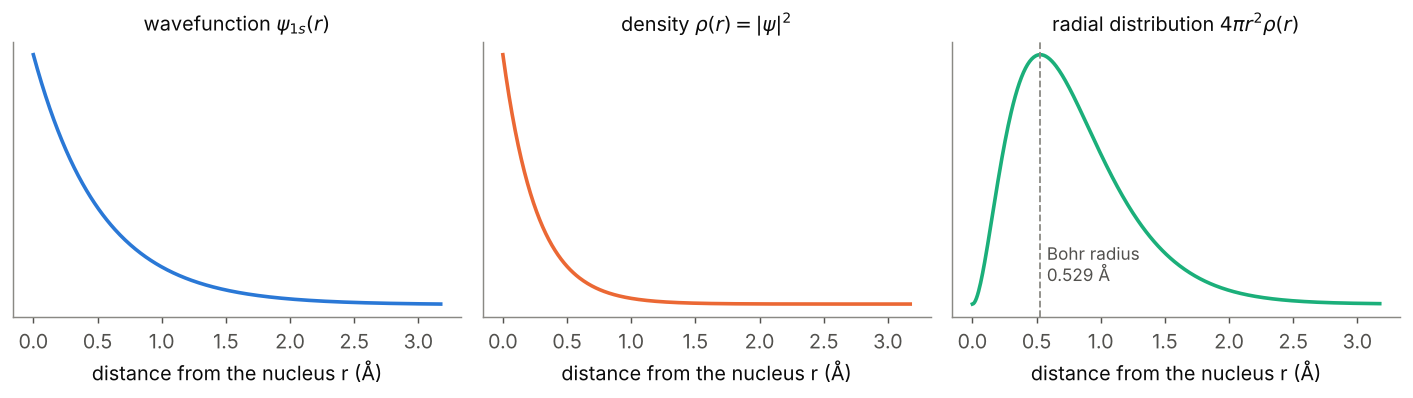

### Basis sets

For molecules the Schrödinger equation cannot be solved exactly. A QM program writes each orbital as a combination of simple functions centred on the atoms, the **basis set**, and finds the best combination. For practical reasons these functions are Gaussians ($e^{-\alpha r^2}$), which have the wrong shape: the figure shows that more Gaussians are needed to reproduce the exact $1s$ orbital, especially its cusp at the nucleus and its tail.

More basis functions = more flexibility = more accurate, but more expensive. We use the *def2* family: **def2-SVP** (small), **def2-TZVP** (medium), **def2-QZVPP** (large).


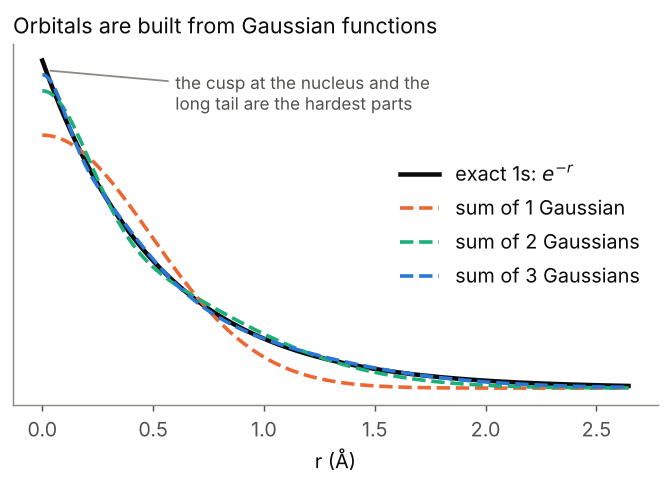

### How the program finds the electrons: the SCF

With more than one electron, each electron feels the repulsion of all the others, so its orbital depends on the orbitals of the others. The equations are solved iteratively, the **self-consistent field** (SCF) procedure: start from a guess, compute the density, compute the potential it creates, find new orbitals, and repeat until nothing changes.


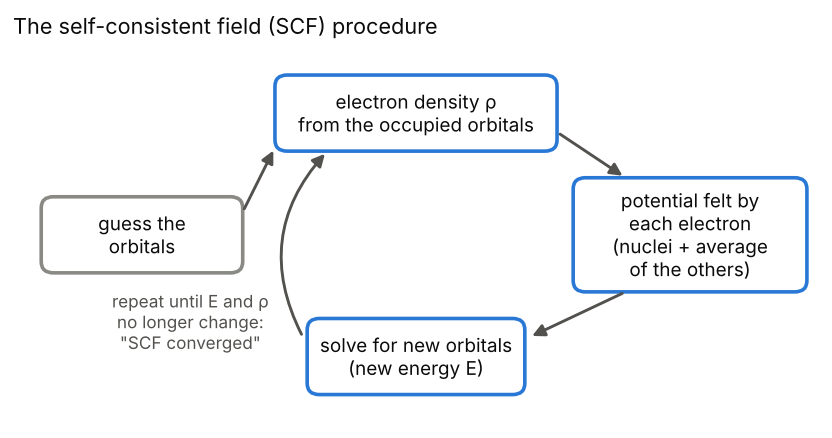

The two main families of methods differ in how they treat the interaction between electrons:

*   **Hartree–Fock (HF)**: each electron moves in the *average* field of the others. It misses the fact that electrons avoid each other instantaneously (the **electron correlation**).
*   **Density functional theory (DFT)**: the energy is written as a function (a *functional*) of the electron density. In principle exact, in practice the functional must be approximated, and there are hundreds of them. We use **r$^2$SCAN-3c**, a modern DFT method designed to be accurate and fast (it comes with its own basis set and small corrections). DFT is the workhorse of quantum chemistry.

### The first calculation

ORCA reads an **input** with the method, the basis set and the molecule, and writes a long **output**. Here: one H atom (charge 0, *multiplicity* 2, see Part 2), HF method, def2-SVP basis set (`TightSCF` asks for a tight convergence of the SCF).

In [ ]:
inp = '''
! HF def2-SVP TightSCF
* xyz 0 2
H  0.0 0.0 0.0
*
'''
out = run_orca('H_HF_def2-SVP', inp, folder='H')
print('Final energy:', final_energy(out), 'Eh')

Open the output (`T07/H/H_HF_def2-SVP/H_HF_def2-SVP.out`, double-click on it in the file browser on the left). It is long, but organised in sections. Look for:

*   `BASIS SET INFORMATION`: how many basis functions are used;
*   the table of the SCF iterations (after `ORCA LEAN-SCF`): the energy goes down at each iteration and the change (`Delta-E`) becomes smaller and smaller, until `SCF CONVERGED AFTER ... CYCLES`;
*   `ORBITAL ENERGIES`: the energy of each orbital and how many electrons occupy it (OCC);
*   `FINAL SINGLE POINT ENERGY`, at the end.

Here is the SCF part:

In [ ]:
text = open(out).read()
print(text[text.index('Iteration    Energy'):text.index('TOTAL SCF ENERGY')])

Now we repeat the calculation with the three basis sets, and with DFT (r$^2$SCAN-3c, which has its own basis set). It takes a few seconds.

In [ ]:
results = []
for method in ['HF def2-SVP', 'HF def2-TZVP', 'HF def2-QZVPP', 'r2SCAN-3c']:
    name = 'H_' + method.replace(' ', '_')
    out = run_orca(name, f'! {method} TightSCF\n* xyz 0 2\nH 0 0 0\n*', folder='H')
    results.append((method, final_energy(out)))

print(f"{'method':16s} {'E (Eh)':>10s} {'E - exact (kcal/mol)':>22s}")
for method, e in results:
    print(f'{method:16s} {e:10.6f} {(e + 0.5) * HARTREE2KCAL:22.2f}')

With the largest basis set HF is almost exact: for **one** electron there is no other electron to correlate with, and HF is exact apart from the basis set. DFT is not exact even for this simple case: with approximate functionals the electron interacts a little with its own density (the *self-interaction error*). Keep in mind the size of these errors in kcal/mol, compared with the energy of a hydrogen bond (a few kcal/mol).

### The electron density

ORCA can write the density on a 3D grid of points in a *cube* file (`%plots` block, see the function `plots_block` above). Here we use a fine grid (80 points per side):

In [ ]:
inp = '! HF def2-QZVPP TightSCF\n' + plots_block(['ElDens("H.eldens.cube")'], npoints=80) + '* xyz 0 2\nH 0 0 0\n*'
out = run_orca('H_density', inp, folder='H')
show_cube('H/H_density/H.eldens.cube', isovalue=0.01)

The surface encloses the region where the density is larger than the *isovalue*. Change it (0.2, 0.05, 0.01, 0.001 electrons/bohr$^3$): the density decays quickly but never becomes exactly zero, the atom has no sharp edge. You can also open the cube file with VMD (`File → New Molecule`, then `Graphical Representations → Isosurface`) or ChimeraX (`open H.eldens.cube`).

A cube file is just a 3D array of numbers, so we can analyse it: here we compute $\rho$ and the radial distribution as a function of the distance from the nucleus and compare them with the exact result.

In [ ]:
origin, axes, rho = read_cube('H/H_density/H.eldens.cube')
idx = np.indices(rho.shape).reshape(3, -1).T
points = origin + idx @ axes                 # coordinates (bohr) of the grid points
r = np.linalg.norm(points, axis=1)           # distance from the nucleus, in bohr
rho = rho.ravel()
print('number of electrons in the box:', rho.sum() * abs(np.linalg.det(axes)))

order = np.argsort(r)
r_ex = np.linspace(0, r.max(), 300)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].semilogy(r[order] * BOHR2ANG, rho[order], '.', ms=2, label='ORCA, HF/def2-QZVPP')
ax[0].semilogy(r_ex * BOHR2ANG, np.exp(-2 * r_ex) / np.pi, 'k-', label='exact')
ax[0].set_xlabel('r (Å)'); ax[0].set_ylabel(r'$\rho$ (bohr$^{-3}$, log scale)'); ax[0].legend()
ax[1].plot(r[order] * BOHR2ANG, 4 * np.pi * r[order]**2 * rho[order], '.', ms=2)
ax[1].plot(r_ex * BOHR2ANG, 4 * r_ex**2 * np.exp(-2 * r_ex), 'k-')
ax[1].axvline(BOHR2ANG, ls='--', c='grey')
ax[1].set_xlabel('r (Å)'); ax[1].set_ylabel(r'$4\pi r^2 \rho$ (bohr$^{-1}$)')
plt.tight_layout(); plt.show()

The agreement is excellent close to the nucleus. Far from it (look at the logarithmic scale) the calculated density decays too fast: the Gaussian basis functions decay faster than the exact exponential.

## Part 2: the carbon atom and the electron spin

Electrons have a **spin**, up (↑) or down (↓). Each orbital can host at most two electrons, with opposite spin (Pauli principle). The total spin $S$ is ½ for each unpaired electron, and the **multiplicity** $2S+1$ is the number we give to ORCA: 1 (*singlet*, all electrons paired), 2 (*doublet*, one unpaired electron, like the H atom), 3 (*triplet*, two unpaired electrons with the same spin), and so on.

Carbon has 6 electrons: $1s^2 2s^2 2p^2$. How do the two $2p$ electrons arrange themselves in the three $2p$ orbitals? And what if one $2s$ electron moves to $2p$ ($2s^1 2p^3$, four unpaired electrons, the configuration used to explain the four bonds of carbon)?


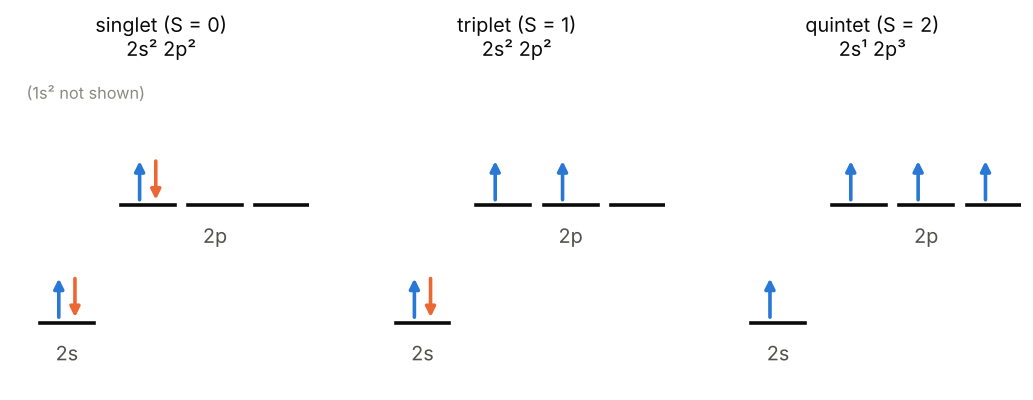

We compute the energy of the three spin states with r$^2$SCAN-3c and write the **spin density** (density of ↑ electrons minus density of ↓ electrons), which shows where the unpaired electrons are.

In [ ]:
energies = {}
for mult in [1, 3, 5]:
    plots = plots_block([f'SpinDens("C_{mult}.spindens.cube")']) if mult > 1 else ''
    out = run_orca(f'C_mult{mult}', f'! r2SCAN-3c TightSCF\n{plots}* xyz 0 {mult}\nC 0 0 0\n*', folder='C')
    energies[mult] = final_energy(out)
for mult in energies:
    print(f'multiplicity {mult}: E - E(triplet) = {(energies[mult] - energies[3]) * HARTREE2EV:6.2f} eV')

The triplet is the most stable: two electrons with the same spin in different orbitals stay away from each other (Hund's rule). The quintet (experimentally 4.18 eV above the ground state) is much higher: promoting a $2s$ electron costs energy, and in molecules it is paid back by forming four bonds.

The spin density of the triplet:

In [ ]:
show_cube('C/C_mult3/C_3.spindens.cube', isovalue=0.01)

## Part 3: the chemical bond in H$_2$

When two H atoms approach, their $1s$ orbitals combine into two **molecular orbitals**: a **bonding** orbital $\sigma_g$ (sum of the two $1s$, lower in energy) and an **antibonding** orbital $\sigma_u^*$ (difference, higher in energy). The two electrons, with opposite spin, go into the bonding orbital: their energy is lower than in the separated atoms, and this is the bond.


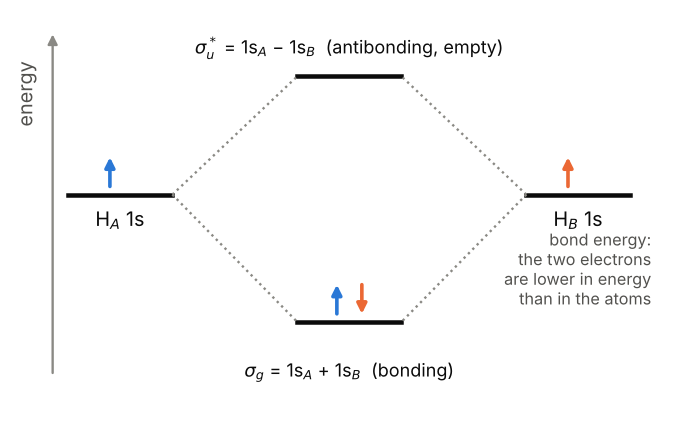

We compute H$_2$ at its experimental bond length (0.741 Å) with HF and the def2-TZVP basis set, and write the two orbitals (in ORCA orbitals are numbered from 0: orbital 0 is $\sigma_g$, orbital 1 is $\sigma_u^*$) and the density. To see what the bond does to the electrons, we also compute two isolated H atoms at the same positions, on the same grid (the box is given in bohr).

In [ ]:
grid = '''%plots
  dim1 60
  dim2 60
  dim3 80
  min1 -4.0
  max1  4.0
  min2 -4.0
  max2  4.0
  min3 -5.0
  max3  5.0
  Format Gaussian_Cube
'''
out = run_orca('H2_orbitals', '! HF def2-TZVP TightSCF\n' + grid +
               '  MO("H2.mo0.cube",0,0);\n  MO("H2.mo1.cube",1,0);\n  ElDens("H2.eldens.cube");\nend\n' +
               '* xyz 0 1\nH 0 0 -0.3705\nH 0 0 0.3705\n*', folder='H2')
for i, z in enumerate([-0.3705, 0.3705]):
    run_orca(f'H_atom{i}', '! HF def2-TZVP TightSCF\n' + grid + f'  ElDens("H{i}.eldens.cube");\nend\n* xyz 0 2\nH 0 0 {z}\n*', folder='H2')
for occ, e in orbital_energies(out)[:2]:
    print(f'orbital with {occ:.0f} electrons: energy {e:8.2f} eV')

The bonding orbital (left) and the antibonding orbital (right). Red and blue are the positive and negative parts of the wavefunction: the antibonding orbital changes sign between the nuclei, so it has a *node*, a plane where the electron is never found.

In [ ]:
show_cube('H2/H2_orbitals/H2.mo0.cube', isovalue=0.05, signed=True)
show_cube('H2/H2_orbitals/H2.mo1.cube', isovalue=0.05, signed=True)

Where do the electrons go when the bond forms? The **density difference** $\Delta\rho = \rho(\mathrm{H_2}) - \rho(\mathrm{H}) - \rho(\mathrm{H})$ is positive (red) where the bond accumulates electrons and negative (blue) where it removes them. We plot it on a plane that contains the two nuclei (+).

In [ ]:
o, ax, rho_h2 = read_cube('H2/H2_orbitals/H2.eldens.cube')
_, _, rho_a = read_cube('H2/H_atom0/H0.eldens.cube')
_, _, rho_b = read_cube('H2/H_atom1/H1.eldens.cube')
drho = rho_h2 - rho_a - rho_b
mid = rho_h2.shape[1] // 2                                          # the plane y = 0
x = (o[0] + np.arange(rho_h2.shape[0]) * ax[0, 0]) * BOHR2ANG
z = (o[2] + np.arange(rho_h2.shape[2]) * ax[2, 2]) * BOHR2ANG
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
c0 = axs[0].contourf(z, x, rho_h2[:, mid, :], levels=np.linspace(0, 0.3, 31), cmap='Blues')
axs[0].set_title(r'$\rho$(H$_2$)'); plt.colorbar(c0, ax=axs[0])
lim = np.abs(drho[:, mid, :]).max()
c1 = axs[1].contourf(z, x, drho[:, mid, :], levels=np.linspace(-lim, lim, 31), cmap='RdBu_r')
axs[1].set_title(r'$\Delta\rho = \rho$(H$_2$) $- \rho$(H) $- \rho$(H)'); plt.colorbar(c1, ax=axs[1])
for a in axs:
    a.plot([-0.3705, 0.3705], [0, 0], 'k+', ms=12); a.set_xlabel('z (Å)'); a.set_ylabel('x (Å)'); a.set_aspect('equal')
plt.tight_layout(); plt.show()

### Breaking the bond: the energy as a function of the distance

The nuclei are about 2000 times heavier than the electrons and move much more slowly: for each position of the nuclei, the electrons adjust instantly (the *Born–Oppenheimer approximation*). So a QM calculation gives the energy as a function of the positions of the nuclei, the **potential energy surface**. For a diatomic molecule it is a curve: its minimum is the bond length, its depth is the bond energy, and its curvature gives the vibrational frequency. A force field approximates it with a spring (the harmonic approximation), which is fine close to the minimum, but can't break the bond.


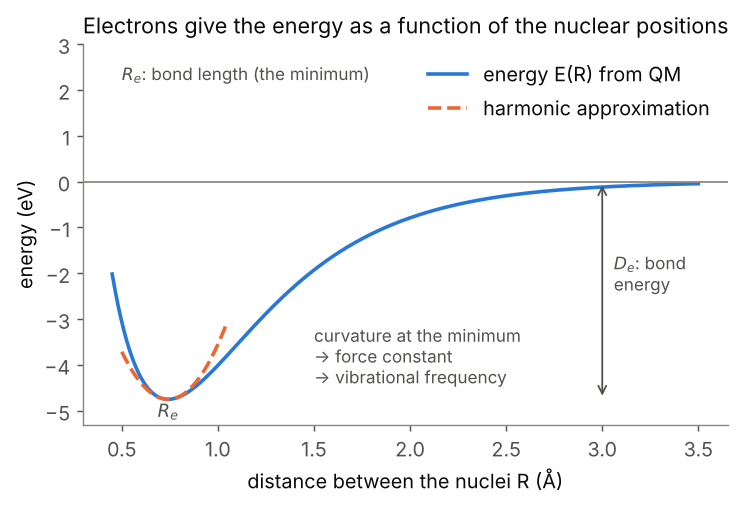

We compute the curve of H$_2$ from 0.5 to 4 Å with three methods:

*   **RHF**: Hartree–Fock in which the two electrons share the same orbital ("restricted");
*   **UHF**: Hartree–Fock in which the ↑ and ↓ electrons can have different orbitals ("unrestricted"). To find this solution ORCA starts from the triplet and then flips the spin of one electron (`FlipSpin`);
*   **CCSD** (coupled cluster): a method that includes the electron correlation. For two electrons it is exact (within the basis set): it is our reference.

The 45 calculations take about 30 seconds.

In [ ]:
distances = np.array([0.5, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9, 1.0, 1.2, 1.4, 1.7, 2.0, 2.5, 3.0, 4.0])
methods = {'RHF': '! HF def2-TZVP TightSCF',
           'UHF': '! UHF def2-TZVP TightSCF\n%scf\n  FlipSpin 1\n  FinalMs 0.0\nend',
           'CCSD': '! CCSD def2-TZVP TightSCF'}
curves = {}
for m, keywords in methods.items():
    mult = 3 if m == 'UHF' else 1           # FlipSpin starts from the triplet and flips one electron
    curves[m] = np.array([final_energy(run_orca(f'H2_{m}_{d:.2f}', keywords + f'\n* xyz 0 {mult}\nH 0 0 0\nH 0 0 {d}\n*', folder='H2'))
                          for d in distances])
# the energy of two separated H atoms with the same basis set (HF is exact for one electron)
e_atom = final_energy(run_orca('H_HF_def2-TZVP', '! HF def2-TZVP TightSCF\n* xyz 0 2\nH 0 0 0\n*', folder='H2'))

fig, ax = plt.subplots(figsize=(6.5, 4))
for m, e in curves.items():
    ax.plot(distances, (e - 2 * e_atom) * HARTREE2EV, 'o-', label=m)
ax.axhline(0, c='grey', ls='--', lw=1); ax.set_ylim(-5, 4)
ax.set_xlabel('H–H distance (Å)'); ax.set_ylabel('E(H$_2$) − 2 E(H) (eV)'); ax.legend()
plt.tight_layout(); plt.show()
for m, e in curves.items():
    i = np.argmin(e)
    print(f'{m:5s}: minimum at {distances[i]:.2f} Å, bond energy {-(e[i] - 2 * e_atom) * HARTREE2EV:5.2f} eV, '
          f'energy at 4 Å {(e[-1] - 2 * e_atom) * HARTREE2EV:5.2f} eV')

The experimental bond length is 0.741 Å and the bond energy is 4.75 eV (109.5 kcal/mol). Notice:

*   all methods give a good bond length;
*   HF underestimates the bond energy: the missing part is the **correlation energy**, recovered by CCSD (the remaining error is due to the basis set);
*   RHF does not go back to two H atoms at large distance. With the two electrons forced into the same orbital $\sigma_g = 1s_A + 1s_B$, half of the time both electrons are on the same atom (H$^+$ + H$^-$), even when the atoms are far apart;
*   UHF breaks the bond correctly, by putting the ↑ electron on one atom and the ↓ electron on the other.

Breaking bonds is the hard part of quantum chemistry, and needs care in the choice of the method. Molecules close to their equilibrium structure, as in the rest of this practical, are much easier.

## Part 4: a real molecule, water

### Shape and vibrations

We start from a rough structure of water and let ORCA move the atoms downhill on the potential energy surface until it reaches the minimum (geometry optimisation, `Opt`). Then it computes the curvature of the surface at the minimum, which gives the **vibrational frequencies** (`Freq`), the frequencies of light absorbed in an infrared (IR) spectrum. `CHELPG` asks for a type of atomic charges (see below), and the `%plots` block writes the HOMO and LUMO (see below). It takes about 10 seconds.

In [ ]:
water = '''* xyz 0 1
O   0.000   0.000   0.000
H   0.000   0.800   0.600
H   0.000  -0.800   0.600
*'''
inp = '! r2SCAN-3c Opt Freq CHELPG TightSCF\n' + plots_block(['MO("water.homo.cube",4,0)', 'MO("water.lumo.cube",5,0)']) + water
out = run_orca('water_r2SCAN-3c', inp, folder='water')
show_molecule('water/water_r2SCAN-3c/water_r2SCAN-3c.xyz')

In [ ]:
def geometry(xyzfile):
    # O-H distance and H-O-H angle of a water molecule (atoms in the order O, H, H)
    el, x = read_xyz(xyzfile)
    d1, d2 = x[1] - x[0], x[2] - x[0]
    angle = np.degrees(np.arccos(d1 @ d2 / np.linalg.norm(d1) / np.linalg.norm(d2)))
    return np.linalg.norm(d1), angle

def frequencies(out):
    # vibrational frequencies (cm-1) and IR intensities (km/mol) from the IR SPECTRUM table
    text = open(out).read().split('IR SPECTRUM')[-1].split('\n\n\n')[0]
    rows = re.findall(r'^\s*(\d+):\s+(-?\d+\.\d+)\s+\S+\s+(\d+\.\d+)', text, re.M)
    return np.array([[float(f), float(i)] for _, f, i in rows])

r_oh, angle = geometry('water/water_r2SCAN-3c/water_r2SCAN-3c.xyz')
print(f'O-H distance = {r_oh:.3f} Å   H-O-H angle = {angle:.1f} degrees   (experiment: 0.957 Å, 104.5 degrees)')
print(f'dipole moment = {dipole(out):.2f} D                         (experiment: 1.85 D)')
freq = frequencies(out)
for (f, i), name in zip(freq, ['bending', 'symmetric stretching', 'antisymmetric stretching']):
    print(f'{name:25s} {f:6.0f} cm-1   IR intensity {i:5.1f} km/mol')

Water has three vibrations. The experimental frequencies in the gas phase are 1595, 3657 and 3756 cm$^{-1}$; they are lower than the computed ones (by about 4%) mainly because the real potential is not exactly harmonic. ORCA writes a movie of each vibration with the program `orca_pltvib`: the modes 0–5 are the translations and rotations of the whole molecule, 6–8 are the vibrations.

In [ ]:
def show_mode(out, mode, width=400, height=300):
    folder, name = os.path.split(out)
    subprocess.run([os.path.join(ORCA_DIR, 'orca_pltvib'), name, str(mode)], cwd=folder, capture_output=True)
    view = py3Dmol.view(width=width, height=height)
    view.addModelsAsFrames(open(f'{out}.v{mode:03d}.xyz').read(), 'xyz')
    view.setStyle({'stick': {'radius': 0.15}, 'sphere': {'scale': 0.25}})
    view.animate({'loop': 'backAndForth'})
    view.zoomTo()
    return view.show()

show_mode(out, 6)     # try also 7 and 8

### Molecular orbitals

The two most important orbitals of a molecule are the **HOMO** (highest occupied molecular orbital) and the **LUMO** (lowest unoccupied molecular orbital): the electrons of the HOMO are the easiest to remove or to share (water uses them to accept hydrogen bonds), the LUMO is where an added or excited electron goes (Part 6). Water has 10 electrons in 5 orbitals (numbered 0–4): the HOMO is orbital 4, the LUMO orbital 5. The HOMO of water is one of the two *lone pairs* of the oxygen.

In [ ]:
show_cube('water/water_r2SCAN-3c/water.homo.cube', isovalue=0.05, signed=True)
show_cube('water/water_r2SCAN-3c/water.lumo.cube', isovalue=0.05, signed=True)

### Atomic charges

Oxygen attracts electrons more than hydrogen, so the molecule is polar: slightly negative on O and slightly positive on the H atoms. **Atomic charges** summarise this with one number per atom. They are not observables: there are many ways to divide the electron density among the atoms. *Mulliken* charges divide it according to the basis functions; *CHELPG* charges are fitted to reproduce the electrostatic potential around the molecule, the same idea used to derive the charges of AMBER force fields. Compare them with the charges of the water models used in MD.

In [ ]:
for kind in ['MULLIKEN', 'CHELPG']:
    print(f'{kind:10s}', '  '.join(f'{el} {q:+.3f}' for el, q in charges(out, kind)))
print(f"{'TIP3P':10s} O -0.834  H +0.417  H +0.417")

### How good is the method?

The choice of the method is always a compromise between accuracy and cost. Let's compare r$^2$SCAN-3c with HF and a small basis set, for the same optimisation and frequency calculation.

In [ ]:
print(f"{'method':14s} {'O-H (Å)':>8s} {'angle':>7s} {'bending (cm-1)':>15s} {'dipole (D)':>11s} {'time (s)':>9s}")
for name, method in [('water_HF', 'HF def2-SVP'), ('water_r2SCAN-3c', 'r2SCAN-3c')]:
    out = run_orca(name, f'! {method} Opt Freq TightSCF\n' + water, folder='water') if name == 'water_HF' else \
          os.path.join('water', name, name + '.out')
    r_oh, angle = geometry(os.path.join('water', name, name + '.xyz'))
    print(f'{method:14s} {r_oh:8.3f} {angle:7.1f} {frequencies(out)[0, 0]:15.0f} {dipole(out):11.2f} {wall_time(out):9.1f}')
print(f"{'experiment':14s} {0.957:8.3f} {104.5:7.1f} {'1595 (1649 harmonic)':>15s} {1.85:11.2f}")

### Two molecules: the hydrogen bond

The energy of the interaction between two molecules A and B is a difference:

$$\Delta E = E(AB) - E(A) - E(B)$$

where the three energies are computed at the geometry the molecules have in the complex. These are small differences between large numbers, so we convert them to kcal/mol.

There is a subtle problem. In the complex, molecule A can borrow the basis functions of molecule B to improve the description of its own electrons, which lowers $E(AB)$ artificially: the interaction looks stronger than it is. This is the **basis-set superposition error** (BSSE). The fix is the **counterpoise correction**: $E(A)$ and $E(B)$ are computed with the basis functions of the whole complex, by placing *ghost atoms* (basis functions without nucleus and electrons) where the partner was. In ORCA a ghost atom is written with a colon after the element, e.g. `H:`.


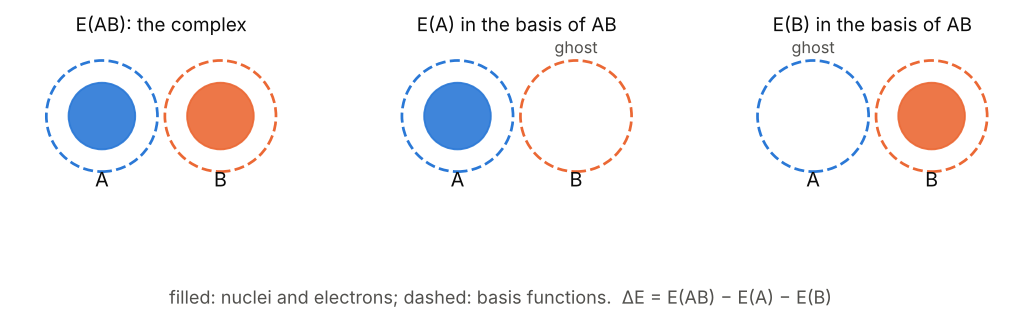

The geometry of the water dimer comes from the S22 database, a set of 22 complexes of biological interest with very accurate reference interaction energies. The reference for the water dimer is −5.02 kcal/mol. The folder `Data/qm/s22` contains all of them: **GROUP 1** uses them in the report.

In [ ]:
import pandas as pd
s22 = pd.read_csv(os.path.join(QM_DIR, 's22', 's22x5_reference.csv'))
s22[s22.scale == 1.0][['id', 'system', 'nA', 'nB', 'Eint_ref_kcal']]

In [ ]:
def interaction_energy(xyzfile, nA, method, folder, counterpoise=True, q=(0, 0, 0)):
    # interaction energy (kcal/mol) of a dimer whose first nA atoms are molecule A and the others molecule B
    # q = (charge of AB, charge of A, charge of B); all species are closed-shell singlets
    nat = int(open(xyzfile).readline())
    tag = os.path.basename(xyzfile).replace('.xyz', '') + '_' + re.sub(r'[^A-Za-z0-9_+-]', '', method.replace(' ', '_'))   # no spaces, / or () in file names
    A, B = range(nA), range(nA, nat)
    jobs = {'AB': (xyz_block(xyzfile), q[0])}
    if counterpoise:                                     # monomers in the basis of the dimer: the partner is made of ghost atoms
        jobs['A'] = (xyz_block(xyzfile, ghost=B), q[1])
        jobs['B'] = (xyz_block(xyzfile, ghost=A), q[2])
    else:                                                # monomers in their own basis: the partner is removed
        lines = xyz_block(xyzfile).splitlines()
        jobs['A'] = ('\n'.join(lines[:nA]), q[1])
        jobs['B'] = ('\n'.join(lines[nA:]), q[2])
    E = {}
    for k, (coords, charge) in jobs.items():
        name = f'{tag}_{k}' + ('_cp' if counterpoise and k != 'AB' else '')
        out = run_orca(name, f'! {method} TightSCF\n* xyz {charge} 1\n{coords}\n*', folder=folder)
        E[k] = final_energy(out)
    return (E['AB'] - E['A'] - E['B']) * HARTREE2KCAL

In [ ]:
xyz = os.path.join(QM_DIR, 's22', '02_Water_dimer_1.0.xyz')
show_molecule(xyz)
for method in ['HF def2-SVP', 'HF def2-TZVP', 'r2SCAN-3c']:
    e_nocp = interaction_energy(xyz, 3, method, 'water_dimer', counterpoise=False)
    e_cp = interaction_energy(xyz, 3, method, 'water_dimer', counterpoise=True)
    print(f'{method:14s}  without CP: {e_nocp:6.2f}   with CP: {e_cp:6.2f}   BSSE: {e_cp - e_nocp:5.2f} kcal/mol')
print('reference: -5.02 kcal/mol')

The BSSE is large with the small basis set, and becomes small with the larger one. (r$^2$SCAN-3c contains an empirical correction for it, so the counterpoise correction changes little.) Notice also that HF already gives a reasonable interaction energy: the hydrogen bond is mostly electrostatic. This is not true for all interactions, as GROUP 1 will discover.

## Part 5: dynamics, a proton on the move

### Molecular dynamics with quantum forces

So far the nuclei were fixed. As in classical MD (T04), we can let them move with Newton's equations, but now the forces come from a QM calculation at every step: this is **ab initio molecular dynamics**. It is very expensive (one QM calculation per femtosecond!) but bonds can break and form during the simulation.


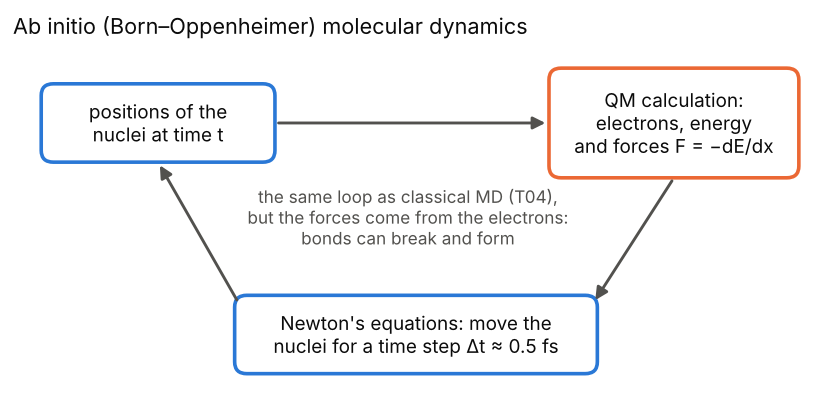

### Protons in water: the Grotthuss mechanism

An excess proton in water is not attached to one water molecule: it jumps from one molecule to the next along chains of hydrogen bonds. In each jump an O–H bond breaks and a new one forms, so that a "hydronium" H$_3$O$^+$ is passed on like a relay, and the positive charge moves much faster than any single atom. This is why protons diffuse in water about five times faster than other ions. Proteins use the same trick: chains of water molecules ("proton wires") carry protons inside bacteriorhodopsin, cytochrome *c* oxidase, the ATP synthase, and to the histidine that recycles the active site of carbonic anhydrase.


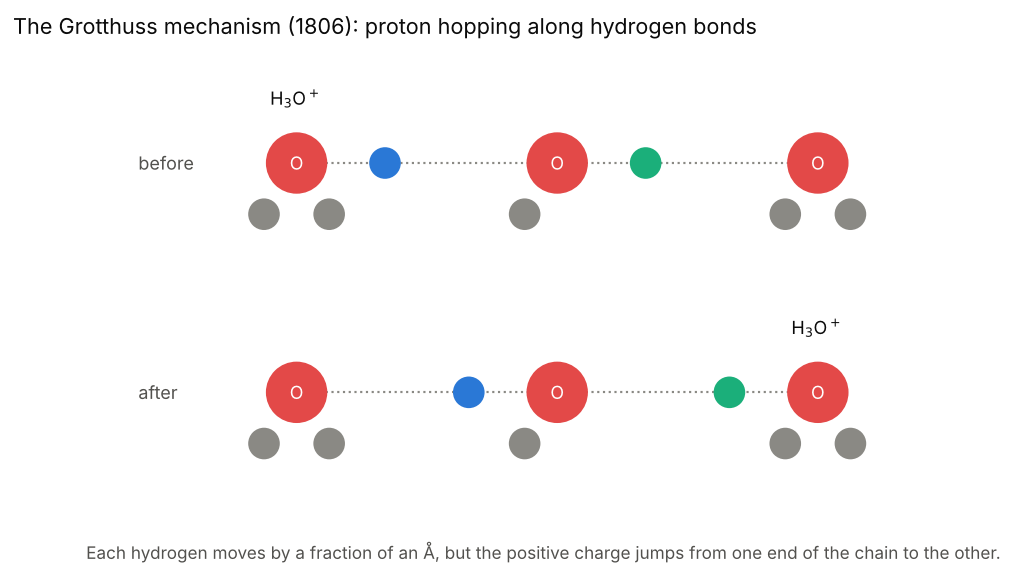

Our system is a small proton wire: a hydronium ion H$_3$O$^+$, three water molecules, and an ammonia molecule NH$_3$ at the other end (like the amine of a lysine side chain; ammonia is a stronger base than water and is the final acceptor of the proton). We start from a structure prepared so that the proton is still on the first water (the structure was relaxed keeping the O–H bonds along the wire fixed), and run 0.5 ps of dynamics at 300 K.

To make this fast enough we use **GFN2-xTB**, a *semiempirical* QM method: it keeps the electrons and the chemistry (bonds can still break), but simplifies the equations and uses parameters fitted to more accurate calculations, so it is about 1000 times faster than DFT. The `%md` block of ORCA defines the simulation: time step, initial velocities at 300 K (`Randomize` sets the random seed used to draw them), thermostat, how often to save the positions, and the number of steps. It takes about 2–3 minutes.

In [ ]:
wire = os.path.join(QM_DIR, 'water_wire.xyz')
show_molecule(wire)

In [ ]:
def md_input(xyzfile, charge, steps=1000, seed=1, temperature=300):
    return f'''! Native-GFN2-XTB MD
%md
  Timestep 0.5_fs
  Randomize {seed}
  Initvel {temperature}_K
  Thermostat Berendsen {temperature}_K Timecon 50_fs
  Dump Position Stride 2 Filename "trajectory.xyz"
  Run {steps}
end
* xyz {charge} 1
{xyz_block(xyzfile)}
*'''

out = run_orca('wire_seed1', md_input(wire, charge=1, seed=1), folder='md')

The trajectory (one frame every 1 fs) is in `md/wire_seed1/trajectory.xyz`. You can play it here, or open it with VMD (with the representation `DynamicBonds`, the bonds are drawn according to the current distances: you will see them break and form).

In [ ]:
def read_trajectory(xyzfile):
    lines = open(xyzfile).read().splitlines()
    n = int(lines[0])
    elements = [l.split()[0] for l in lines[2:2 + n]]
    frames = [np.array([[float(v) for v in l.split()[1:4]] for l in lines[i + 2:i + 2 + n]])
              for i in range(0, len(lines) - n - 1, n + 2)]
    return np.array(elements), np.array(frames)

def show_trajectory(xyzfile, stride=5, width=500, height=300):
    lines = open(xyzfile).read().splitlines()
    n = int(lines[0])
    frames = [lines[i:i + n + 2] for i in range(0, len(lines) - n - 1, n + 2)][::stride]
    view = py3Dmol.view(width=width, height=height)
    view.addModelsAsFrames('\n'.join('\n'.join(f) for f in frames), 'xyz')
    view.setStyle({'stick': {'radius': 0.12}, 'sphere': {'scale': 0.25}})
    view.animate({'loop': 'forward', 'interval': 60})
    view.zoomTo()
    return view.show()

traj = 'md/wire_seed1/trajectory.xyz'
show_trajectory(traj)

To follow the proton we assign each hydrogen to the closest heavy atom (O or N) and look for the one that has an extra hydrogen: an O with three H (H$_3$O$^+$) or the N with four (NH$_4^+$). The plot shows where the excess proton is, frame by frame. Heavy atoms are numbered along the wire: 0 is the starting hydronium, 1–3 the water molecules, 4 the nitrogen.

In [ ]:
def proton_position(elements, frames):
    heavy = np.where(elements != 'H')[0]
    hydrogens = np.where(elements == 'H')[0]
    normal = np.array([3 if elements[i] == 'N' else 2 for i in heavy])     # H atoms of NH3 and H2O
    where = []
    for x in frames:
        d = np.linalg.norm(x[hydrogens][:, None] - x[heavy][None], axis=2)
        count = np.bincount(d.argmin(axis=1), minlength=len(heavy))
        extra = np.where(count > normal)[0]
        where.append(extra[0] if len(extra) == 1 else np.nan)   # nan: the proton is shared between two molecules
    return np.array(where)

elements, frames = read_trajectory(traj)
time_fs = np.arange(len(frames)) * 1.0                  # one frame every 1 fs
pos = proton_position(elements, frames)
fig, ax = plt.subplots(figsize=(8, 3))
ax.step(time_fs, pos, where='post')
ax.set_yticks(range(5)); ax.set_yticklabels(['H$_3$O$^+$ (0)', 'water 1', 'water 2', 'water 3', 'NH$_4^+$ (4)'])
ax.set_xlabel('time (fs)'); ax.set_title('where is the excess proton?', loc='left')
plt.tight_layout(); plt.show()
first = np.argmax(pos == 4) if np.any(pos == 4) else None
print('the proton reaches the ammonia after', f'{time_fs[first]:.0f} fs' if first is not None else '... it does not reach it in this simulation')

The proton goes back and forth between neighbouring water molecules, travels along the wire, and is finally captured by the ammonia (NH$_4^+$), the strongest base. Each jump takes a few femtoseconds. A classical force field could never describe this: the bonds are fixed in its topology.

Run the simulation again with a different seed (e.g. `seed=2`, saving it in a new folder `wire_seed2`): the initial velocities change, and so does the path of the proton. How long does it take to reach the ammonia? Molecular processes are stochastic: to get a rate you would need many trajectories.

The energies along the simulation are in a CSV file: the potential energy goes down when the proton reaches the base (the reaction releases energy, which the thermostat removes).

In [ ]:
ener = pd.read_csv('md/wire_seed1/wire_seed1-md-ener.csv', sep=';', skipinitialspace=True)
ener.columns = [c.strip('# ').strip() for c in ener.columns]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(ener['Sim. Time'], (ener['E_Pot'] - ener['E_Pot'][0]) * HARTREE2KCAL)
ax[0].set_xlabel('time (fs)'); ax[0].set_ylabel('potential energy (kcal/mol)')
ax[1].plot(ener['Sim. Time'], ener['Temp'])
ax[1].set_xlabel('time (fs)'); ax[1].set_ylabel('temperature (K)')
plt.tight_layout(); plt.show()

## Part 6: light, why molecules have a colour

A molecule absorbs a photon when the energy of the photon, $E = hc/\lambda$, matches the energy needed to move an electron from an occupied to an empty orbital, typically from the HOMO to the LUMO. Visible light goes from about 400 nm (violet, 3.1 eV) to 700 nm (red, 1.8 eV): molecules whose HOMO–LUMO gap is smaller than about 3 eV absorb visible light and look coloured (of the complementary colour of the light they absorb). Most biomolecules have larger gaps and absorb only in the UV.


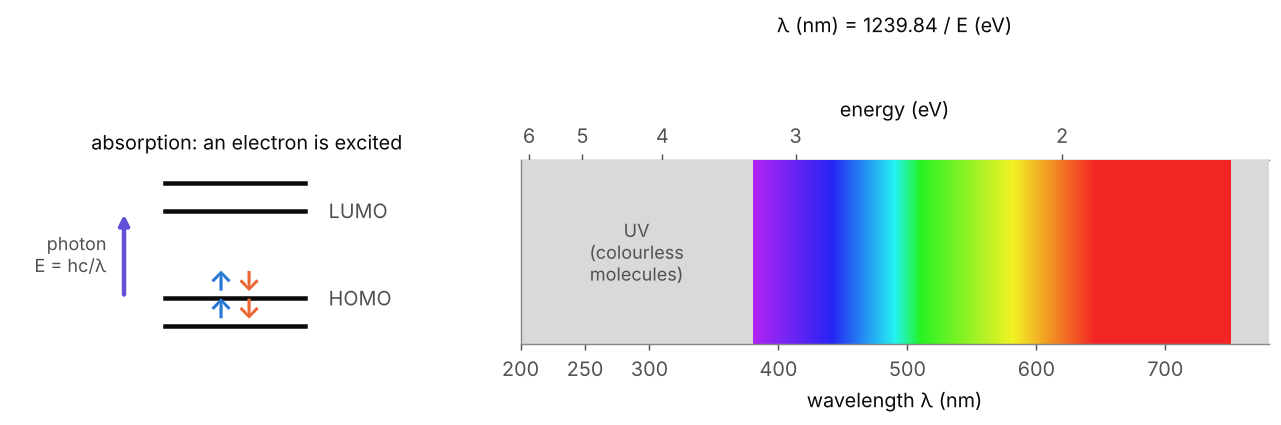

The excited state is not just "one electron moved to the LUMO": the other electrons respond. **Time-dependent DFT** (TD-DFT) computes the excitation energies and, for each excited state, the **oscillator strength** $f$, a number proportional to the intensity of the absorption. States with $f \approx 0$ are *dark*: they exist but they don't absorb light. For TD-DFT we use the functional **CAM-B3LYP**, designed for excited states, and a basis set with diffuse functions (def2-SVPD).

We start from formaldehyde, H$_2$C=O: we optimise it and compute its first 6 excited states (`%tddft` block).

In [ ]:
formaldehyde = '''* xyz 0 1
C   0.000   0.000   0.000
O   0.000   0.000   1.210
H   0.000   0.940  -0.590
H   0.000  -0.940  -0.590
*'''
opt = run_orca('formaldehyde_opt', '! r2SCAN-3c Opt TightSCF\n' + formaldehyde, folder='tddft')
xyz = 'tddft/formaldehyde_opt/formaldehyde_opt.xyz'
inp = '! CAM-B3LYP def2-SVPD TightSCF\n%tddft\n  NRoots 6\nend\n' + \
      plots_block(['MO("formaldehyde.homo.cube",7,0)', 'MO("formaldehyde.lumo.cube",8,0)']) + \
      '* xyz 0 1\n' + xyz_block(xyz) + '\n*'
out = run_orca('formaldehyde_tddft', inp, folder='tddft')

In [ ]:
def excitations(out):
    # excited states from the absorption spectrum table: list of (energy eV, wavelength nm, oscillator strength)
    text = open(out).read().split('ABSORPTION SPECTRUM VIA TRANSITION ELECTRIC DIPOLE MOMENTS')[1].split('\n\n')[0]
    rows = []
    for l in text.splitlines():
        if '->' in l:
            f = l.split('->')[1].split()
            rows.append((float(f[1]), float(f[3]), float(f[4])))
    return np.array(rows)

def transitions(out):
    # the orbital contributions to each excited state, as printed by ORCA (e.g. "7a -> 8a : 0.98")
    text = open(out).read().split('EXCITED STATES')[1].split('ABSORPTION SPECTRUM')[0]
    for block in re.split(r'\n(?=STATE\s+\d+:)', text)[1:]:
        head = block.splitlines()[0]
        contr = re.findall(r'(\d+a\s+->\s+\d+a)\s+:\s+(\d\.\d+)', block)
        print(head.split('<S**2>')[0].strip(), '  ', ',  '.join(f'{t} ({c})' for t, c in contr))

def spectrum(states, fwhm=0.3, emin=1.5, emax=8.0):
    # absorption spectrum: a Gaussian of width fwhm (eV) for each state, with area proportional to f
    E = np.linspace(emin, emax, 1000)
    sigma = fwhm / 2.3548
    eps = sum(f * np.exp(-(E - e)**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi)) for e, lam, f in states)
    return E, eps

def colour_of(states, fwhm=0.3, max_absorbance=1.0):
    # colour of the light transmitted by a solution of the molecule (white light in, absorbed bands removed),
    # with the concentration chosen so that the strongest band has absorbance max_absorbance
    lam = np.arange(380.0, 781.0, 1.0)                        # visible wavelengths (nm)
    def g(x, mu, s1, s2):                                    # CIE 1931 colour matching functions (Wyman et al. 2013)
        return np.exp(-0.5 * ((x - mu) / np.where(x < mu, s1, s2))**2)
    xbar = 1.056 * g(lam, 599.8, 37.9, 31.0) + 0.362 * g(lam, 442.0, 16.0, 26.7) - 0.065 * g(lam, 501.1, 20.4, 26.2)
    ybar = 0.821 * g(lam, 568.8, 46.9, 40.5) + 0.286 * g(lam, 530.9, 16.3, 31.1)
    zbar = 1.217 * g(lam, 437.0, 11.8, 36.0) + 0.681 * g(lam, 459.0, 26.0, 13.8)
    sigma = fwhm / 2.3548
    E = 1239.84 / lam
    band = lambda e: np.exp(-(E - e)**2 / (2 * sigma**2))
    E_all = np.linspace(1.0, 12.0, 4000)
    peak = max(sum(f * np.exp(-(E_all - e)**2 / (2 * sigma**2)) for e, _, f in states).max(), 1e-12)
    absorbance = max_absorbance * sum(f * band(e) for e, _, f in states) / peak
    T = 10**(-absorbance)
    XYZ = np.array([np.sum(T * c) for c in (xbar, ybar, zbar)]) / np.sum(ybar)
    M = np.array([[3.2406, -1.5372, -0.4986], [-0.9689, 1.8758, 0.0415], [0.0557, -0.2040, 1.0570]])
    white = M @ (np.array([np.sum(c) for c in (xbar, ybar, zbar)]) / np.sum(ybar))
    rgb = np.clip(M @ XYZ / white, 0, 1)                     # white light -> (1, 1, 1)
    rgb = np.where(rgb <= 0.0031308, 12.92 * rgb, 1.055 * rgb**(1 / 2.4) - 0.055)
    return np.clip(rgb, 0, 1)

In [ ]:
states = excitations(out)
print('state  E (eV)  wavelength (nm)  f')
for i, (e, lam, f) in enumerate(states, start=1):
    print(f'{i:5d} {e:7.2f} {lam:12.0f} {f:12.4f}')
print()
transitions(out)       # which orbitals are involved (formaldehyde has 16 electrons: the HOMO is orbital 7, the LUMO 8)

The first excited state (about 4 eV, 310 nm, UV) is the HOMO → LUMO transition (7a → 8a): an electron moves from a lone pair of the oxygen (the HOMO) to the antibonding $\pi^*$ orbital of the C=O bond (the LUMO). Its oscillator strength is zero: the two orbitals are perpendicular to each other, and the transition is "forbidden". Formaldehyde, like all simple carbonyl groups (and the peptide bond), is colourless.

In [ ]:
show_cube('tddft/formaldehyde_tddft/formaldehyde.homo.cube', isovalue=0.05, signed=True)
show_cube('tddft/formaldehyde_tddft/formaldehyde.lumo.cube', isovalue=0.05, signed=True)

### Conjugation: alternating single and double bonds

Now *trans*-butadiene, CH$_2$=CH–CH=CH$_2$: two conjugated double bonds, whose $\pi$ electrons are spread over the whole molecule. Its strong $\pi \rightarrow \pi^*$ absorption (experiment: 5.9 eV, 210 nm) has a large oscillator strength. The longer the conjugated chain, the smaller the gap and the longer the wavelength: GROUP 2 will see where this leads with retinal, the molecule of vision.

In [ ]:
butadiene = '''* xyz 0 1
C   -1.80   0.42   0.0
C   -0.60  -0.20   0.0
C    0.60   0.20   0.0
C    1.80  -0.42   0.0
H   -2.72  -0.16   0.0
H   -1.88   1.51   0.0
H   -0.55  -1.29   0.0
H    0.55   1.29   0.0
H    2.72   0.16   0.0
H    1.88  -1.51   0.0
*'''
opt = run_orca('butadiene_opt', '! r2SCAN-3c Opt TightSCF\n' + butadiene, folder='tddft')
xyz = 'tddft/butadiene_opt/butadiene_opt.xyz'
out = run_orca('butadiene_tddft', '! CAM-B3LYP def2-SVPD TightSCF\n%tddft\n  NRoots 6\nend\n* xyz 0 1\n' + xyz_block(xyz) + '\n*', folder='tddft')
transitions(out)

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, label in [('formaldehyde_tddft', 'formaldehyde'), ('butadiene_tddft', 'butadiene')]:
    st = excitations(f'tddft/{name}/{name}.out')
    E, eps = spectrum(st, emin=3, emax=10)
    line, = ax.plot(E, eps, label=label)
    ax.vlines(st[:, 0], 0, st[:, 2] * 3, colors=line.get_color())
ax.set_xlabel('excitation energy (eV)'); ax.set_ylabel('absorption (arb. units)'); ax.legend()
secax = ax.secondary_xaxis('top', functions=(lambda e: 1239.84 / np.maximum(e, 1e-3), lambda l: 1239.84 / np.maximum(l, 1e-3)))
secax.set_xlabel('wavelength (nm)')
plt.tight_layout(); plt.show()

The spectrum is drawn by placing a bell-shaped band (a Gaussian) on each excited state, with an area proportional to its oscillator strength: in a real spectrum the bands are broad because of the vibrations of the molecule and of the solvent. The computed absorption of butadiene (≈ 6.4 eV) is about 0.5 eV above the experimental one: errors of a few tenths of eV are typical of TD-DFT.

### What colour is it?

The colour we see is the light that is **not** absorbed. White light contains all the visible wavelengths; if a molecule absorbs some of them, the transmitted light lacks them, and we see the *complementary* colour. A solution that absorbs blue light (≈ 450 nm) looks yellow; one that absorbs green (≈ 530 nm) looks magenta.

The function `colour_of` turns a computed spectrum into a colour: it takes white light, removes what the molecule absorbs at each visible wavelength (using the bands of the spectrum, with the concentration chosen so that the strongest band absorbs 90% of the light), and converts the transmitted light into the colour perceived by the human eye (using the CIE colour-matching functions, which describe the sensitivity of the three types of cones of the retina). The top row shows our two molecules; the bottom row shows the colour of a hypothetical molecule with a single band at different wavelengths.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 3))
for k, name in enumerate(['formaldehyde', 'butadiene']):
    ax.add_patch(plt.Rectangle((k * 2.4, 1.3), 1.0, 1.0, color=colour_of(excitations(f'tddft/{name}_tddft/{name}_tddft.out')), ec='grey'))
    ax.text(k * 2.4 + 0.5, 1.15, name, ha='center', va='top')
for k, lam in enumerate([350, 400, 430, 450, 480, 500, 530, 560, 600, 650]):
    ax.add_patch(plt.Rectangle((k * 1.2, 0), 1.0, 0.8, color=colour_of(np.array([[1239.84 / lam, lam, 1.0]])), ec='grey'))
    ax.text(k * 1.2 + 0.5, -0.1, f'absorbs at\n{lam} nm', ha='center', va='top', fontsize=9)
ax.set_xlim(-0.1, 12); ax.set_ylim(-0.8, 2.4); ax.axis('off')
plt.show()

What do we learn?

*   **Formaldehyde and butadiene are colourless**: all their absorption is in the UV, far from the visible. This is true of most biomolecules: amino acids, nucleotides, sugars and lipids absorb only below 300 nm, and proteins and DNA solutions are transparent.
*   **To be coloured, a molecule must absorb at wavelengths longer than ≈ 400 nm**, i.e. it needs an excitation energy below ≈ 3 eV. In practice this requires a long chain of conjugated double bonds (the gap between HOMO and LUMO shrinks as the electrons are spread over a longer chain), sometimes with charges or metals. Nature's coloured molecules are exactly of this type: carotenoids (orange, absorb ≈ 450–480 nm), flavins (yellow, ≈ 450 nm), retinal bound to rhodopsin (absorbs ≈ 500 nm: rhodopsin was called "visual purple"), heme (red), chlorophyll (green: it absorbs red and blue light, and transmits green).
*   **The colour is very sensitive to the excitation energy.** In the visible, an error of 0.3 eV (typical of TD-DFT) moves the absorption by 50–80 nm, enough to change the predicted colour from yellow to red. Calculations are reliable for *trends* (longer chain → redder absorption, a protonation shifts the band in one direction), less for the exact colour.

GROUP 2 uses these tools in the report, on the chromophores of GFP, rhodopsin and flavoproteins.

## What next

You are ready for the report. The training questions are answered by everybody; then **GROUP 1** goes on with the interaction energies of the S22 complexes (Part 4) and **GROUP 2** with the excited states of biological chromophores (Part 6). The report notebook has the same setup and helper functions, and finds the calculations of the training in your `T07` folder on Google Drive.